# 02 - Het model van de scout

Hoe wegen scouts de cues en hoe consistent doen ze dat? Dit notebook volgt de werkwijze van de tutorial (Peringa et al., 2025), aan de kant van de scout.

| Tutorial | Hier |
|---|---|
| Oordeel $Y_s$ | `performance` (1-4 sterren) |
| Cues $X_1 \dots X_k$ | gemiddelde score per categorie: 7 voor veldspelers, 4 voor keepers |
| Weging $b_s$ | OLS-regressie per scout |
| Relatieve belangrijkheid | dominantieanalyse, herschaald naar 100% |
| Cognitieve controle $R_s$ | correlatie tussen $Y_s$ en $\hat{Y}_s$, met bootstrap-betrouwbaarheidsinterval |
| Gemiddelde $R_s$ | random-effects meta-analyse van de correlaties |

Er is geen prestatiecriterium $Y_e$, dus $r_a$, $R_e$, $r_m$, $G$ en $C$ vallen buiten dit onderzoek.

**Verschillen met de tutorial om in het achterhoofd te houden**
- De tutorial heeft 50 oordelen per scout op 4 cues. Hier zijn dat er 14 tot 33 op 7 cues, dus het overfittingsrisico is veel groter. Daarom staat naast $R_s$ ook een leave-one-out-versie, die niet in de tutorial voorkomt.
- De tutorial bekijkt één positie. Hier beoordeelt een scout meerdere posities, en "Offensive" bevat per positie andere vragen.
- In de tutorial liggen de cues vooraf vast. Hier vult de scout cues en oordeel zelf in hetzelfde formulier in, wat $R_s$ kan opdrijven.

## 1. Data

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CLEAN_DIR = Path("data") / "clean"

FIELD_CUES = ["Offensive", "Defensive", "Offensive Transition", "Defensive Transition",
              "Set Pieces", "Physical", "Mental"]
GK_CUES = ["2D", "3D", "1v1", "Distribution"]

# Voorlopige drempel: een scout heeft minstens zoveel rapporten per cue nodig
MIN_REPORTS_PER_CUE = 2
N_BOOTSTRAP = 2000
RANDOM_SEED = 42

pd.set_option("display.max_columns", None, "display.max_rows", 100)

CUE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
BLUE, ORANGE = CUE_COLORS[:2]
SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10, "text.color": INK,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_MUTED, "axes.titlesize": 11,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "xtick.bottom": False, "ytick.left": False,
    "legend.frameon": False,
})

In [2]:
cues = pd.read_csv(CLEAN_DIR / "cues_per_category.csv", encoding="utf-8-sig")

# Zoals in de tutorial: alleen rapporten met een waarde op elke cue
field = cues[~cues["is_goalkeeper"]].dropna(subset=FIELD_CUES).copy()
keepers = cues[cues["is_goalkeeper"]].dropna(subset=GK_CUES).copy()


def eligible_scouts(df, cue_names):
    sizes = df.groupby("scout_id").size().sort_values(ascending=False)
    return sizes[sizes >= MIN_REPORTS_PER_CUE * len(cue_names)]


field_scouts = eligible_scouts(field, FIELD_CUES)
keeper_scouts = eligible_scouts(keepers, GK_CUES)

print(f"Veldspelers: {len(field)} volledige rapporten, {field['scout_id'].nunique()} scouts")
print(f"  in de analyse: {len(field_scouts)} scouts, {field_scouts.sum()} rapporten")
print(f"Keepers: {len(keepers)} volledige rapporten, {keepers['scout_id'].nunique()} scouts")
print(f"  in de analyse: {len(keeper_scouts)} scout(s), {keeper_scouts.sum()} rapporten")

Veldspelers: 162 volledige rapporten, 11 scouts
  in de analyse: 8 scouts, 154 rapporten
Keepers: 36 volledige rapporten, 5 scouts
  in de analyse: 1 scout(s), 28 rapporten


## 2. Samenhang tussen de cues

Vergelijkbaar met Table 2 in de tutorial. Als cues sterk samenhangen, zeggen regressiegewichten weinig over het belang van een cue. Dat is de reden om dominantieanalyse te gebruiken.

In [3]:
analysis_field = field[field["scout_id"].isin(field_scouts.index)]

# Correlaties binnen scouts, zodat verschillen in strengheid ze niet opdrijven
within_scout = analysis_field[FIELD_CUES + ["performance"]] - analysis_field.groupby("scout_id")[
    FIELD_CUES + ["performance"]
].transform("mean")
within_scout.corr().round(2)

,Offensive,Defensive,Offensive Transition,Defensive Transition,Set Pieces,Physical,Mental,performance
Offensive,1.00,0.38,0.51,0.35,0.24,0.43,0.44,0.61
Defensive,0.38,1.00,0.30,0.58,0.27,0.49,0.46,0.38
Offensive Transition,0.51,0.30,1.00,0.23,0.24,0.22,0.35,0.38
Defensive Transition,0.35,0.58,0.23,1.00,0.18,0.40,0.42,0.21
Set Pieces,0.24,0.27,0.24,0.18,1.00,0.19,0.23,0.10
Physical,0.43,0.49,0.22,0.40,0.19,1.00,0.41,0.39
Mental,0.44,0.46,0.35,0.42,0.23,0.41,1.00,0.43
performance,0.61,0.38,0.38,0.21,0.10,0.39,0.43,1.00


## 3. Functies

In [4]:
def fit_ols(X, y):
    design = np.column_stack([np.ones(len(y)), X])
    coefficients, *_ = np.linalg.lstsq(design, y, rcond=None)
    return coefficients, design @ coefficients


def r_squared(X, y):
    _, fitted = fit_ols(X, y)
    return 1 - np.sum((y - fitted) ** 2) / np.sum((y - y.mean()) ** 2)


def correlation(a, b):
    if np.std(a) == 0 or np.std(b) == 0:
        return np.nan
    return np.corrcoef(a, b)[0, 1]


def general_dominance(X, y):
    """Gemiddelde toename in R2 per cue, over alle deelmodellen (Azen & Budescu, 2003)."""
    k = X.shape[1]
    r2 = {(): 0.0}
    for size in range(1, k + 1):
        for subset in combinations(range(k), size):
            r2[subset] = r_squared(X[:, subset], y)

    scores = []
    for cue in range(k):
        others = [other for other in range(k) if other != cue]
        mean_gain_by_size = [
            np.mean([r2[tuple(sorted(subset + (cue,)))] - r2[subset] for subset in combinations(others, size)])
            for size in range(k)
        ]
        scores.append(np.mean(mean_gain_by_size))
    return np.array(scores)


def bootstrap_rs(X, y, rng):
    n = len(y)
    values = []
    for _ in range(N_BOOTSTRAP):
        sample = rng.integers(0, n, n)
        _, fitted = fit_ols(X[sample], y[sample])
        values.append(correlation(y[sample], fitted))
    return np.nanpercentile(values, [2.5, 97.5])


def leave_one_out_rs(X, y):
    predictions = np.empty(len(y))
    for held_out in range(len(y)):
        train = np.arange(len(y)) != held_out
        coefficients, _ = fit_ols(X[train], y[train])
        predictions[held_out] = coefficients[0] + X[held_out] @ coefficients[1:]
    return correlation(y, predictions)


def fit_scouts(df, cue_names, scouts):
    rng = np.random.default_rng(RANDOM_SEED)
    summary, weights, importance = {}, {}, {}
    for scout_id in scouts:
        scout = df[df["scout_id"] == scout_id]
        X = scout[cue_names].to_numpy(float)
        y = scout["performance"].to_numpy(float)

        coefficients, fitted = fit_ols(X, y)
        dominance = general_dominance(X, y)
        r2 = r_squared(X, y)
        assert np.isclose(dominance.sum(), r2)

        ci_low, ci_high = bootstrap_rs(X, y, rng)
        summary[scout_id] = {
            "n": len(y),
            "spelers": scout["player_id"].nunique(),
            "posities": scout["questionnaire_position"].nunique(),
            "sd_oordeel": y.std(ddof=1),
            "unieke_oordelen": len(np.unique(y)),
            "R_s": correlation(y, fitted),
            "ci_laag": ci_low,
            "ci_hoog": ci_high,
            "R_s_loo": leave_one_out_rs(X, y),
        }
        weights[scout_id] = coefficients[1:]
        importance[scout_id] = dominance / r2 * 100

    summary = pd.DataFrame(summary).T.astype({"n": int, "spelers": int, "posities": int, "unieke_oordelen": int})
    summary = summary.sort_values("R_s", ascending=False)
    summary.index.name = "scout_id"
    weights = pd.DataFrame(weights, index=cue_names).T.loc[summary.index]
    importance = pd.DataFrame(importance, index=cue_names).T.loc[summary.index]
    return summary, weights, importance


def random_effects_mean(correlations, sizes):
    """Random-effects gemiddelde (DerSimonian-Laird) op Fisher z-getransformeerde correlaties."""
    z = np.arctanh(correlations)
    variance = 1 / (sizes - 3)
    fixed_weights = 1 / variance
    fixed_mean = np.sum(fixed_weights * z) / fixed_weights.sum()
    q = np.sum(fixed_weights * (z - fixed_mean) ** 2)
    c = fixed_weights.sum() - np.sum(fixed_weights ** 2) / fixed_weights.sum()
    tau2 = max(0.0, (q - (len(z) - 1)) / c)

    weights = 1 / (variance + tau2)
    mean = np.sum(weights * z) / weights.sum()
    se = np.sqrt(1 / weights.sum())
    return {
        "gemiddelde": np.tanh(mean),
        "ci_laag": np.tanh(mean - 1.96 * se),
        "ci_hoog": np.tanh(mean + 1.96 * se),
        "tau2": tau2,
    }

## 4. Veldspelers: resultaten per scout

Het model per scout voorspelt `performance` uit de zeven cues. Scouts staan gesorteerd van hoogste naar laagste $R_s$.

In [5]:
summary, weights, importance = fit_scouts(field, FIELD_CUES, field_scouts.index)
summary.round(2)

,n,spelers,posities,sd_oordeel,unieke_oordelen,R_s,ci_laag,ci_hoog,R_s_loo
scout_id,,,,,,,,,
19,17,16,7,0.78,3,0.96,0.93,1.00,0.80
20,16,13,8,0.73,3,0.86,0.84,1.00,0.46
15,21,17,8,0.60,3,0.83,0.75,0.99,0.39
16,18,13,9,0.49,2,0.78,0.74,0.99,0.24
13,16,16,8,0.44,3,0.77,0.64,1.00,0.32
30,33,24,9,0.51,2,0.72,0.63,0.91,0.46
14,14,13,4,0.63,3,0.67,0.65,1.00,-0.31
23,19,19,6,0.70,4,0.43,0.42,0.98,-0.36


### 4.1 Cognitieve controle

**$R_s$** meet hoe goed het lineaire model de eigen oordelen van de scout volgt op de data waarop het geschat is. Met weinig rapporten en veel cues valt die waarde per definitie hoog uit.

**$R_s$ leave-one-out** meet hetzelfde, maar voorspelt elk rapport met een model dat op de overige rapporten geschat is. Dat is een strengere schatting. Een groot verschil tussen beide wijst op overfitting.

**Let op bij de intervallen.** De bootstrap volgt de tutorial, maar is hier onbetrouwbaar. In een steekproef met herhaalde rapporten past het model nog beter, waardoor $R_s$ omhoog schuift en de puntschatting soms onderaan het interval belandt. Bij 14 tot 33 rapporten op 7 cues weerspiegelt dat overfitting en geen precisie. Hetzelfde geldt voor het interval rond het gemiddelde: de meta-analyse behandelt $R_s$ als een gewone correlatie.

Scouts met maar twee `unieke_oordelen` gebruiken in deze rapporten in de praktijk een tweedelige schaal, wat hun $R_s$ moeilijker vergelijkbaar maakt.

In [6]:
mean_rs = pd.DataFrame({
    "R_s": random_effects_mean(summary["R_s"].to_numpy(), summary["n"].to_numpy()),
    "R_s leave-one-out": random_effects_mean(summary["R_s_loo"].to_numpy(), summary["n"].to_numpy()),
}).T
mean_rs.round(3)

,gemiddelde,ci_laag,ci_hoog,tau2
R_s,0.794,0.660,0.878,0.107
R_s leave-one-out,0.296,-0.005,0.548,0.135


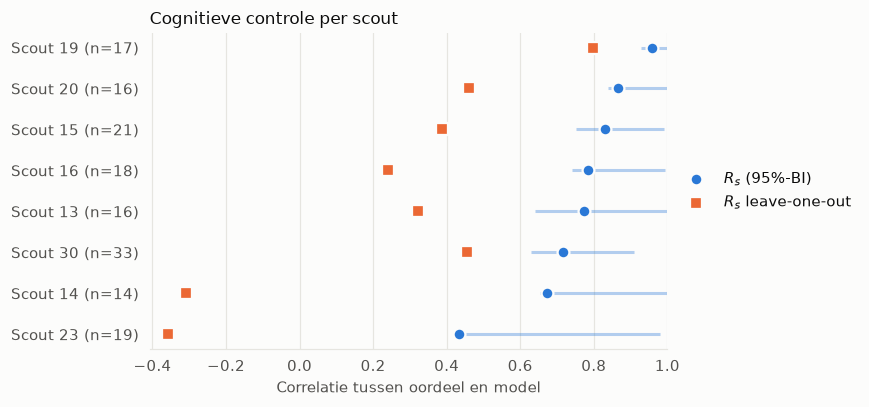

In [7]:
plot_data = summary.sort_values("R_s")
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(plot_data))
ax.grid(axis="x")
ax.hlines(y, plot_data["ci_laag"], plot_data["ci_hoog"], color=BLUE, linewidth=2, alpha=0.35, zorder=1)
ax.scatter(plot_data["R_s"], y, s=60, color=BLUE, edgecolor=SURFACE, linewidth=1.5, label="$R_s$ (95%-BI)", zorder=3)
ax.scatter(plot_data["R_s_loo"], y, s=60, marker="s", color=ORANGE, edgecolor=SURFACE, linewidth=1.5,
           label="$R_s$ leave-one-out", zorder=3)
ax.set_yticks(y, [f"Scout {scout_id} (n={row.n:.0f})" for scout_id, row in plot_data.iterrows()])
ax.set_xlim(min(0, plot_data["R_s_loo"].min() - 0.05), 1)
ax.set_xlabel("Correlatie tussen oordeel en model")
ax.spines["left"].set_visible(False)
ax.set_title("Cognitieve controle per scout")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.tight_layout()
plt.show()

### 4.2 Regressiegewichten $b_s$

Ongestandaardiseerd: het verwachte verschil in `performance` als een cue met één ster stijgt en de andere cues gelijk blijven. Lees deze tabel voorzichtig: door de samenhang tussen de cues en de kleine aantallen zijn de gewichten onstabiel, en negatieve gewichten zijn dan niet ongewoon.

In [8]:
weights.round(2)

,Offensive,Defensive,Offensive Transition,Defensive Transition,Set Pieces,Physical,Mental
19,1.17,0.48,-0.22,-0.60,0.04,0.41,-0.14
20,1.23,0.06,0.37,0.01,0.17,-0.54,0.15
15,0.95,0.04,-0.08,-0.25,-0.04,0.21,0.25
16,-1.27,-0.35,0.46,-0.39,0.02,0.35,1.57
13,1.22,0.94,-0.38,-0.26,-0.30,-0.87,0.71
30,0.38,0.18,0.16,0.03,-0.25,0.16,0.25
14,0.78,-0.01,0.27,-0.03,-0.40,-0.02,0.11
23,-0.26,0.15,0.49,-0.29,0.11,0.31,0.26


### 4.3 Relatieve belangrijkheid

Dominantieanalyse verdeelt de verklaarde variantie over de cues, zoals in Figure 3 en 4 van de tutorial. Per scout telt dit op tot 100%.

Het gemiddelde over scouts is de meest stabiele uitkomst. Verschillen tussen individuele scouts zijn met deze aantallen vooral een eerste indicatie: ook bij dominantieanalyse verdeelt het model de variantie over cues die samenhangen, op basis van weinig rapporten.

In [9]:
importance_overview = pd.concat([
    importance,
    importance.agg(["mean", "min", "max"]).rename(index={"mean": "gemiddeld", "min": "minimum", "max": "maximum"}),
])
importance_overview.round(1)

,Offensive,Defensive,Offensive Transition,Defensive Transition,Set Pieces,Physical,Mental
19,37.0,15.0,9.3,9.0,0.7,18.5,10.7
20,51.1,11.9,19.2,2.4,2.9,6.1,6.4
15,60.2,5.2,2.0,5.2,2.1,19.1,6.1
16,9.6,3.3,26.5,8.8,2.4,3.3,46.2
13,37.1,25.3,4.2,7.0,3.4,15.4,7.6
30,29.3,16.0,14.0,9.0,7.8,8.7,15.2
14,49.7,9.6,15.0,1.1,9.2,2.6,12.8
23,3.0,16.8,23.7,11.6,4.0,11.9,29.1
gemiddeld,34.6,12.9,14.2,6.7,4.0,10.7,16.8
minimum,3.0,3.3,2.0,1.1,0.7,2.6,6.1


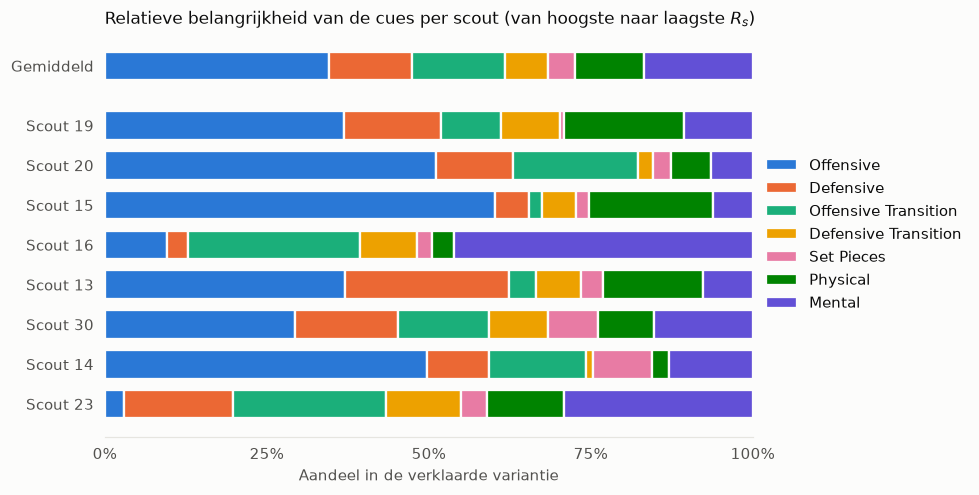

In [10]:
ordered = pd.concat([importance.iloc[::-1], importance.mean().to_frame("Gemiddeld").T])
labels = [f"Scout {scout_id}" for scout_id in ordered.index[:-1]] + ["Gemiddeld"]
y = np.arange(len(ordered), dtype=float)
y[-1] += 0.5

fig, ax = plt.subplots(figsize=(9, 4.6))
left = np.zeros(len(ordered))
for cue, color in zip(FIELD_CUES, CUE_COLORS):
    ax.barh(y, ordered[cue], left=left, height=0.72, color=color, edgecolor=SURFACE, linewidth=1.5, label=cue)
    left += ordered[cue].to_numpy()
ax.set_yticks(y, labels)
ax.set_xlim(0, 100)
ax.set_xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
ax.set_xlabel("Aandeel in de verklaarde variantie")
ax.spines["left"].set_visible(False)
ax.set_title("Relatieve belangrijkheid van de cues per scout (van hoogste naar laagste $R_s$)")
handles, legend_labels = ax.get_legend_handles_labels()
ax.legend(handles, legend_labels, loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.tight_layout()
plt.show()

## 5. Keepers

Keepers hebben andere cues en worden apart bekeken. Slechts één scout heeft genoeg volledige rapporten, dus een gemiddelde over scouts is hier niet mogelijk.

In [11]:
keeper_summary, keeper_weights, keeper_importance = fit_scouts(keepers, GK_CUES, keeper_scouts.index)
display(keeper_summary.round(2))
display(keeper_weights.round(2))
keeper_importance.round(1)

,n,spelers,posities,sd_oordeel,unieke_oordelen,R_s,ci_laag,ci_hoog,R_s_loo
scout_id,,,,,,,,,
22,28,12,1,0.86,4,0.86,0.77,0.94,0.79


,2D,3D,1v1,Distribution
22,0.69,0.38,0.45,0.09


,2D,3D,1v1,Distribution
22,38.9,21.6,22.7,16.7


## 6. Bevindingen uit het rapport *RBFA Scout Consistency*

Samenvatting van het rapport `RBFA_Scout_Consistency.pdf` (seizoen 2025-26). Het rapport kijkt naar **performance** (246 rapporten) en **potential** (219 rapporten) van 12 scouts, met 12 tot 40 rapporten per scout. De resultaten zijn daarom een eerste indicatie en geen eindoordeel.

De methode verschilt van sectie 4, dus de cijfers zijn niet rechtstreeks vergelijkbaar:

- **Per scout** worden alle detailscores van een rapport gemiddeld tot één getal. De consistentiescore (0 tot 1) zegt hoe nauw het globale oordeel dat gemiddelde volgt.
- **Per positie** worden de rapporten van alle scouts samengenomen. Eerst gaat het eigen gemiddelde van elke scout eraf, zodat milde en strenge scouts het resultaat niet bepalen. Vier delen worden apart bekeken: offensief, defensief, fysiek en mentaal. Transitie- en standaardsituatievragen tellen mee bij offensief of defensief. Elk rapport wordt voorspeld uit alle andere rapporten (leave-one-out).
- **Keepers** hebben de categorieën 2D, 3D en Distribution. 1v1 is in 43% van de keepersrapporten leeg gelaten en daarom geen aparte categorie.

Scouts staan hieronder met hun `scout_id`, zoals in de rest van dit notebook.

### 6.1 Consistentie per scout

| Label | Criterium |
|---|---|
| Consistent | score ≥ 0.55 en genoeg rapporten om zeker te zijn dat het globale oordeel de detailscores volgt |
| Moderate | het globale oordeel volgt de detailscores wel, maar minder nauw (score < 0.55) |
| Not consistent | te weinig rapporten of een te zwak patroon om aan te tonen dat het oordeel de detailscores volgt |
| Can't judge | minder dan 15 rapporten, of één en dezelfde score in ≥ 80% van de rapporten |

Hoeveel rapporten nodig zijn, hangt af van hoe duidelijk het patroon is. Hoe minder rapporten, hoe hoger de score moet zijn: met 38 rapporten volstaat 0.32, met 14 rapporten is 0.53 nodig.

| Scout | Rol | Performance | n | Potential | n |
|---|---|---|---|---|---|
| 22 | keeperstrainer | **0.79** Consistent | 40 | **0.57** Consistent | 37 |
| 21 | keeperstrainer | **0.84** Consistent | 15 | 0.59 Can't judge (< 15 rapporten) | 14 |
| 19 | veldscout | **0.66** Consistent | 32 | 0.45 Can't judge (< 15 rapporten) | 12 |
| 15 | veldscout | **0.63** Consistent | 29 | −0.06 Can't judge (zelfde potential in 93%) | – |
| 30 | veldscout | **0.59** Consistent | 31 | 0.35 Not consistent | 31 |
| 20 | veldscout | **0.61** Consistent (weinig rapporten) | 17 | 0.43 Not consistent | 15 |
| 23 | veldscout | 0.50 Moderate (weinig rapporten) | 20 | **0.71** Consistent | 20 |
| 16 | veldscout | 0.45 Not consistent | 19 | 0.50 Moderate (weinig rapporten) | 19 |
| 14 | veldscout | 0.44 Not consistent | 18 | −0.17 Not consistent | – |
| 13 | veldscout | 0.75 Can't judge (een 3 in 87%) | – | 0.41 Can't judge (zelfde potential in 80%) | – |

- Gemiddelde consistentiescore: **0.59 voor performance** en **0.33 voor potential**.
- Bij performance zijn de verschillen tussen scouts zo klein dat ze toeval kunnen zijn. Bij potential zijn sommige scouts duidelijk consistenter dan andere.
- Potential volgt de detailscores minder nauw. Dat is te verwachten: potential gaat over de toekomst en niet alleen over wat een scout in één wedstrijd zag.
- Bij scout 14 volgt het globale potential-oordeel de detailscores niet (−0.17).

### 6.2 Consistentie per positie

Per positie zijn er meer rapporten dan per scout. Met minder dan 25 rapporten kan een positie niet beoordeeld worden.

| Positie | Performance | Potential |
|---|---|---|
| Keepers | Consistent · 0.76 (54) | Moderate · 0.47 (48) |
| Spitsen | Consistent · 0.61 (36) | Not consistent · 0.09 (34) |
| Centrale verdedigers | Moderate · 0.53 (33) | Not consistent · 0.29 (29) |
| Middenvelders | Moderate · 0.50 (61) | Moderate · 0.46 (58) |
| Flankspelers | Moderate · 0.40 (25, net genoeg) | Can't judge (18) |
| Backs | Can't judge (20) | Can't judge (16) |

- Een lage score heeft twee mogelijke oorzaken: de scouts zijn individueel inconsistent op die positie, of elke scout volgt een eigen regel. In beide gevallen helpt een gedeelde beschrijving van wat telt op die positie.
- **Spitsen, potential (0.09)** is het duidelijkste startpunt. Het team weegt vooral Physical (42%) en Mental (35%), maar niet op een gedeelde manier.
- **Centrale verdedigers, potential (0.29)** wordt vooral beoordeeld op Offensive (46%), dus de opbouw, en op Physical (29%), met weinig overeenstemming over het hoe.
- **Middenvelders, potential (0.46)** is matig. Het team leunt duidelijk op Mental (48%), en die gedeelde regel houdt redelijk stand.

### 6.3 Wat telt per positie

Aandeel van elke categorie in het globale oordeel (dominantieanalyse, 100% per rij), alle scouts samen, na verwijdering van het eigen gemiddelde van elke scout.

| Positie | Performance | Potential |
|---|---|---|
| Centrale verdedigers | Offensive 33%, Defensive 29% | Offensive 46%, Physical 29% |
| Backs | Physical 63% | Defensive 45%, Mental 32% |
| Middenvelders | Physical 41%, Offensive 36% | Mental 48%, Defensive 28% |
| Flankspelers | Offensive 43%, Mental 37% | Mental 67% |
| Spitsen | Offensive 72% | Physical 42%, Mental 35% |
| Keepers | 2D 57% | Distribution 44% |

**Over alle posities heen:**

| Groep | Performance | Potential |
|---|---|---|
| Veldspelers | Offensive 41%, Physical 23%, Mental 19%, Defensive 18% | Offensive 52%, Mental 31%, Physical 10%, Defensive 7% |
| Keepers | 2D 57%, Distribution 24%, 3D 19% | Distribution 44%, 3D 31%, 2D 24% |

- **Performance:** offensief spel telt het meest voor de meeste posities, en bij spitsen bijna als enige (72%). Backs worden vooral fysiek beoordeeld (63%). Met dit aantal rapporten kunnen deze verschillen tussen posities nog toeval zijn.
- **Potential:** mentale kwaliteiten domineren bij flankspelers (67%) en middenvelders (48%). Bij backs domineert defensief spel (45%), bij centrale verdedigers offensief spel (46%). Deze verschillen zijn bijna, maar nog niet helemaal, zeker.
- Per scout zien de patronen er heel verschillend uit, maar met 15 tot 40 rapporten per scout zijn die individuele aandelen niet betrouwbaar.

### 6.4 Over het seizoen

| Vraag | Performance | Potential |
|---|---|---|
| Strenger of milder geworden? | geen verandering | geen verandering |
| Meer of minder consistent? | geen duidelijke verandering (0.75 → 0.71) | geen duidelijke verandering (0.67 → 0.51) |
| Andere weging van de categorieën? | geen verandering | Mental telt meer |

- **Mental bij potential:** één ster meer op Mental ging in jan-feb samen met −0.13 sterren op potential, en in maart-juli met +0.52. Die verschuiving is groter dan toeval, maar het is één resultaat tussen verschillende. Bevestig het volgend seizoen.
- Per scout bewegen de scores sterk: scouts 16 en 23 gaan omhoog op performance, scouts 20 en 14 omlaag. Elke seizoenshelft bevat echter maar 7 tot 20 rapporten.

### 6.5 Stabiliteit en overeenstemming

| | Performance | Potential |
|---|---|---|
| Zelfde scout, zelfde speler opnieuw: zelfde score | 35% | 87% |
| Twee scouts, zelfde speler: zelfde score | 35% (toeval: 30%) | 48% (toeval: 44%) |

- Een scout geeft dezelfde speler in 87% van de gevallen opnieuw dezelfde potential. Voor performance is dat 35%, wat logisch is omdat elke wedstrijd anders is.
- Twee scouts geven nauwelijks vaker dezelfde score dan twee willekeurige scores.
- Scouts gebruiken verschillende niveaus. **Scout 30 is het strengst** (gemiddeld 1.4 sterren voor performance), **scout 13 het mildst** (3.0). Dat is één reden waarom ze zelden overeenkomen.
- Geen enkele speler werd door twee scouts in dezelfde wedstrijd beoordeeld. De overeenstemming wordt dus altijd over verschillende wedstrijden vergeleken.

### 6.6 Voorgestelde verbeteringen

**Beoordelingsschaal**

- **Bredere schaal.** Het globale oordeel zou op een schaal van 1 tot 10 kunnen, of van 1 tot 5 met halve sterren. Nu werkt de 4-sterrenschaal voor performance als een 3-puntsschaal (4 sterren in 1% van de rapporten) en voor potential bijna als een 2-puntsschaal (60% krijgt 3 sterren). In Peringa et al. verlaagde het omzetten van 1-10 naar 1-4 sterren, op de manier waarop RBFA-scouts ze gebruiken, de consistentiescore met ongeveer 0.10.
- **Een beschrijving bij elke score**, bijvoorbeeld "3 = zou starten in een Pro League U21-team". Zo betekent een 3 hetzelfde voor elke scout. Dit is de meest directe manier om de lage overeenstemming tussen scouts (35-48%) te verhogen.
- **Potential als concrete voorspelling:** het niveau dat de scout verwacht op 21 jaar (amateur, 1B, squadspeler Pro League, basisspeler Pro League, top-5-competitie, international). Dat spreidt de scores en kan later getoetst worden aan de echte carrière van de speler.

**Dataverzameling**

- **Minimaal 40 rapporten per scout per seizoen.** Met 15 tot 20 rapporten is een score hooguit "somewhat reliable". Met ongeveer 40 zijn de meeste scores betrouwbaar. Om betrouwbaar te zeggen waarop elke scout steunt, zijn er ongeveer 100 nodig.
- **Gedeelde videoclips.** Twee keer per seizoen beoordelen alle scouts dezelfde 30 korte clips met het gewone formulier, waarvan sommige clips enkele weken later terugkomen. Zo zijn scouts op exact dezelfde spelers te vergelijken, en zie je of een scout dezelfde clip twee keer hetzelfde beoordeelt. Vandaag kan geen van beide, omdat elke scout andere spelers ziet.

### 6.7 Belangrijkste conclusies

1. **Performance wordt veel consistenter beoordeeld dan potential.** Gemiddeld volgt het globale performance-oordeel de detailscores duidelijk (0.59). Voor potential is het verband veel zwakker (0.33).
2. **Offensief spel weegt zwaar voor performance, zelfs bij centrale verdedigers.** Het is het grootste aandeel voor de meeste posities. Bij centrale verdedigers telt het iets meer dan verdedigen (33% tegenover 29%).
3. **Mentale kwaliteiten wegen zwaar voor potential.** Ze zijn het tweede belangrijkste deel over alle posities heen (31%) en het belangrijkste bij middenvelders (48%) en flankspelers (67%).
4. **Een bredere schaal met een beschrijving bij elke score kan veel opleveren.** Scouts kunnen dan fijnere verschillen tonen, en een score betekent hetzelfde voor elke scout.
5. **Niet elke scout is even streng.** Scout 30 geeft gemiddeld 1.4 sterren voor performance, scout 13 3.0.

## 7. Mogelijke uitbreidingen

- `potential` als tweede oordeel naast `performance`.
- Multilevel-model, zodat ook scouts met weinig rapporten meetellen en herhaalde metingen per speler in rekening komen.
- Ordinaal model, omdat het oordeel maar vier waarden kan aannemen.
- Gevoeligheidsanalyses: N/A imputeren, zonder bulkimport, zonder straightlining, andere drempel per scout.